In [68]:
import matplotlib.pyplot as plt
import scipy as sp
import numpy as np

rng = np.random.default_rng(42)
np.set_printoptions(linewidth=2000)

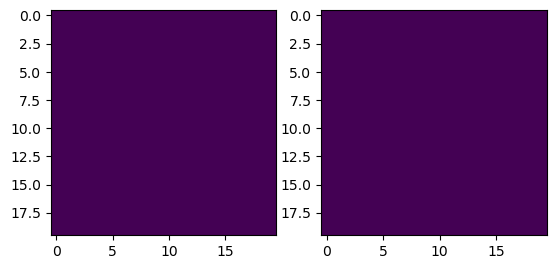

In [200]:
## Important constants
J = 1
k = 1
T = 1


## Generating a random 20x20 lattice. Note that spin up = 1, spin down = -1
lattice = rng.choice((-1, 1), size=(20,20))

## Calculating the Hamiltonian

def hamiltonian(lattice):
    return -J*np.sum(lattice*(np.roll(lattice, 1, axis=0) + np.roll(lattice, 1, axis=1)))



## Metropolis Algorithm

### pick one cell of the lattice, flip it, exclude it from the next chocie



### Flip probability

def prob(lattice, new):
    return np.min(1, np.e**-(hamiltonian(lattice)-hamiltonian(new)/k*T))


### Implementing algo

def Metropolis(lattice, sweeps=100):
    for i in range(sweeps):

        grid = np.indices((20,20))
        ind = np.reshape(np.stack((grid[0], grid[1]), axis=-1), (400,-1))  # hard-coded the lattice size, change later
        rng.shuffle(ind)

        copy = lattice.copy()
        for j in range(400):
            copy[ind[j,0],ind[j,1]] = lattice[ind[j,0],ind[j,1]]  # flip random cell of the copy

    
    
    return copy


test = np.zeros((20,20))
n = Metropolis(test, 1)
m = np.ones((20,20))
m[1,1] = 0

## Plotting
fig, (ax1, ax2) = plt.subplots(1,2)

ax1.imshow(test)
ax2.imshow(n)
